In [16]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [ ]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.1 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.1 MB 2.9 MB/s eta 0:00:03
   ----- ---------------------------------- 1.0/8.1 MB 2.9 MB/s eta 0:00:03
   ------ --------------------------------- 1.3/8.1 MB 2.4 MB/s eta 0:00:03
   ------- -------------------------------- 1.6/8.1 MB 2.0 MB/s eta 0:00:04
   --------- ------------------------------ 1.8/8.1 MB 1.8 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.1 MB 1.7 MB/s eta 0:00:04
   ---------- ----------------------------- 2.1/8.1 MB 1.7 MB/s eta 0:00:04
   ----------- ---------------------------- 2.4/8.1 MB 1.4 MB/s eta 0:00:05
   ------------ --------------------------- 2.6/8.1 MB 1.5 MB/s eta 0:00:04
   -------------- ------------------------- 2.9/8.1 MB 1.4 MB/s eta 0:00:04
   --------------- ------------------------ 3.1/8.1 MB 1.4 MB/s eta 0:00:04
   --------------


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
df=pd.read_csv('computers.csv')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Units    14 non-null     int64
 1   Minutes  14 non-null     int64
dtypes: int64(2)
memory usage: 356.0 bytes


In [10]:
mean_value=df['Minutes'].mean()
mean_value

np.float64(97.21428571428571)

In [11]:
x = df[['Units']]
y = df['Minutes']

In [12]:
model = LinearRegression()
model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [13]:
intercept = model.intercept_
coefficient = model.coef_[0]

print(f'Intercept: {intercept}')
print(f'Coefficient: {coefficient}')

Intercept: 4.161654135338296
Coefficient: 15.508771929824569


In [21]:
df['Predicted_Minutes'] = model.predict(x)

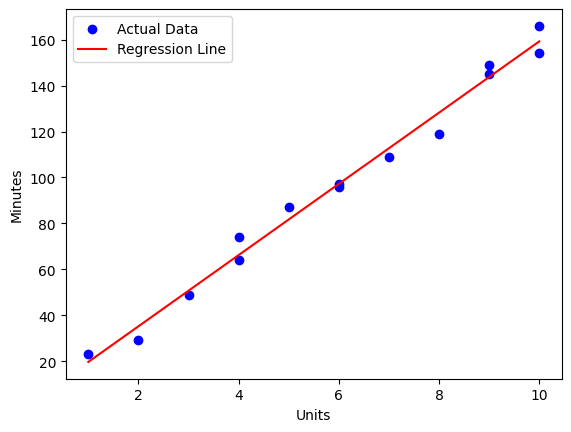

In [22]:
plt.scatter(df['Units'], df['Minutes'], color='blue', label='Actual Data')
plt.plot(df['Units'], df['Predicted_Minutes'], color='red', label='Regression Line')
plt.xlabel('Units')
plt.ylabel('Minutes')
plt.legend()
plt.show()

In [23]:
r2 = r2_score(y, df['Predicted_Minutes'])
print(f'R-squared: {r2}')

R-squared: 0.9874371980620736


Exercise 2: Multiple Linear Regression Model

In [27]:
data = pd.read_csv('std_marks_data.csv')
data.head()

,hours,age,internet,marks
0,6.84,15,0,78.64
1,6.56,20,1,88.80
2,NaN,21,1,88.90
3,8.67,22,1,98.99
4,7.55,17,1,92.34


In [30]:
data.isnull().sum()

hours       0
age         0
internet    0
marks       0
dtype: int64

In [29]:
data.fillna(data.mean(), inplace=True)

In [31]:
x = data[['hours', 'age', 'internet']]
y = data['marks']

In [32]:
model = LinearRegression()
model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [33]:
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 57.9450911613433
Coefficients: [1.25998261 0.32935904 3.11097722]


In [34]:
new_data = pd.DataFrame({
    'hours': [5],
    'age': [20],
    'internet': [1]
})

predicted_marks = model.predict(new_data)
print(f'Predicted Marks: {predicted_marks[0]}')

Predicted Marks: 73.94316212097485


Exercise 3: Build Logistic Regression Model

In [35]:
dj = pd.read_csv('chd_data.csv')
dj.head()

,age,chd
0,20,0
1,23,0
2,24,0
3,25,1
4,25,0


In [36]:
dj.isnull().sum()

age    0
chd    0
dtype: int64

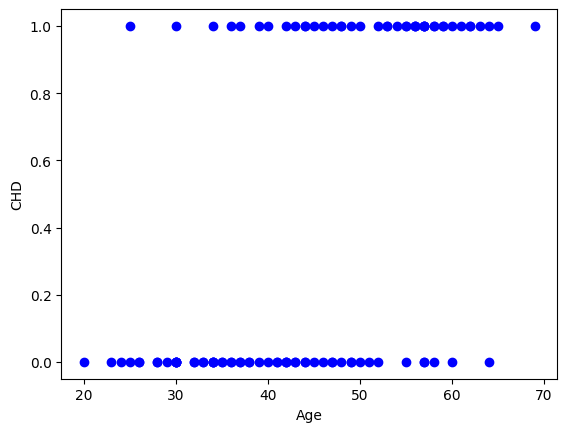

In [37]:
plt.scatter(dj['age'], dj['chd'], color='blue')
plt.xlabel('Age')
plt.ylabel('CHD')
plt.show()

In [38]:
x = dj[['age']]
y = dj['chd']

In [40]:
from sklearn.model_selection import train_test_split


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [41]:
model = LinearRegression()
model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [42]:
print("intercept:", model.intercept_)
print("coefficient:", model.coef_)

intercept: -0.5379603516067275
coefficient: [0.02181073]


In [50]:
sample_age = pd.DataFrame({'age': [50]})
probabilities = model.predict_proba(sample_age)

print("Probability of No CHD:", probabilities[0][0])
print("Probability of CHD:", probabilities[0][1])


Probability of No CHD: 0.4483065815610542
Probability of CHD: 0.5516934184389458


In [51]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy:", accuracy_score(y_test, test_pred))


NameError: name 'X_train' is not defined